In [1]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

import cartopy.crs as ccrs
import cartopy.feature as cf
import matplotlib.colors as colors
import matplotlib.patches as mpatches
import matplotlib.transforms as mtransforms
import matplotlib.ticker as ticker

from dask.diagnostics import ProgressBar

In [2]:
path_clim = '/jetfs/scratch/psplechtna/thesisdata/mse_climatology_3.0/'
filename_clim = 'mse_hourly_climatology.zarr'

In [3]:
clim = xr.open_mfdataset(path_clim+filename_clim, 
                             engine='zarr', concat_dim='time', combine='nested')

In [4]:
clim.mse

<xarray.DataArray 'mse' (time: 1, dayofyear: 124, hour: 24, height: 51,
                         latitude: 141, longitude: 720)> Size: 62GB
dask.array<getitem, shape=(1, 124, 24, 51, 141, 720), dtype=float32, chunksize=(1, 10, 1, 51, 141, 720), chunktype=numpy.ndarray>
Coordinates:
  * dayofyear  (dayofyear) int32 496B 136 137 138 139 140 ... 256 257 258 259
  * hour       (hour) int64 192B 0 1 2 3 4 5 6 7 8 ... 16 17 18 19 20 21 22 23
  * height     (height) int64 408B 20 50 100 200 300 ... 11000 12000 15000 20000
  * latitude   (latitude) float64 1kB 90.0 89.5 89.0 88.5 ... 21.0 20.5 20.0
  * longitude  (longitude) float64 6kB -179.5 -179.0 -178.5 ... 179.5 180.0
Dimensions without coordinates: time

In [5]:
clim=clim.mse.sel(latitude=slice(90,45), time=0)

In [6]:
clim_50=clim.sel(height=50).mean(dim=['hour', 'dayofyear'])

In [7]:
clim_5000=clim.sel(height=5000).mean(dim=['hour', 'dayofyear'])

In [23]:
clim_vert = clim.sel(latitude=slice(90,60)).mean(dim=['latitude', 'longitude', 'hour', 'dayofyear'])

In [24]:
with ProgressBar():
    clim_vert = clim_vert.load()

[########################################] | 100% Completed | 178.53 s


In [25]:
with ProgressBar():
    clim_5000 = clim_5000.load()

In [26]:
with ProgressBar():
    clim_50 = clim_50.load()

In [27]:
clim_vert

<xarray.DataArray 'mse' (height: 51)> Size: 204B
array([289374.47, 289514.34, 289775.47, 290286.47, 290654.03, 291066.5 ,
       291545.88, 292063.9 , 292596.22, 293129.53, 293638.88, 294127.34,
       294588.03, 295021.62, 295426.62, 295820.84, 296201.78, 296523.5 ,
       296830.2 , 297198.62, 297476.47, 297781.6 , 298744.53, 299349.78,
       299947.88, 300542.78, 301132.9 , 301718.53, 302295.53, 302855.1 ,
       303397.7 , 303946.38, 304508.06, 305048.53, 305553.56, 306072.12,
       306596.16, 308920.84, 310080.28, 311199.72, 312335.53, 313571.53,
       314999.97, 316756.12, 319021.47, 322007.22, 325895.8 , 335893.88,
       347312.12, 377547.53, 425834.25], dtype=float32)
Coordinates:
  * height   (height) int64 408B 20 50 100 200 300 ... 11000 12000 15000 20000

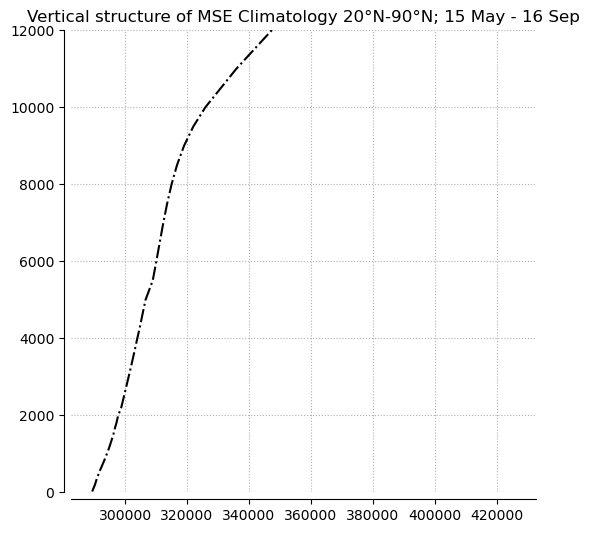

In [28]:
fig, ax = plt.subplots(figsize=(6,6))
ax.plot(clim_vert, clim_vert.height, '-.k')
ax.set_title('Vertical structure of MSE Climatology 20°N-90°N; 15 May - 16 Sep')
ax.grid(linestyle=':')
ax.set_ylim(0,12000)
#ax.set_xlim(290000,330000)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
spine_offset=5
ax.spines.left.set_position(('outward', spine_offset))
ax.spines.bottom.set_position(('outward', spine_offset))

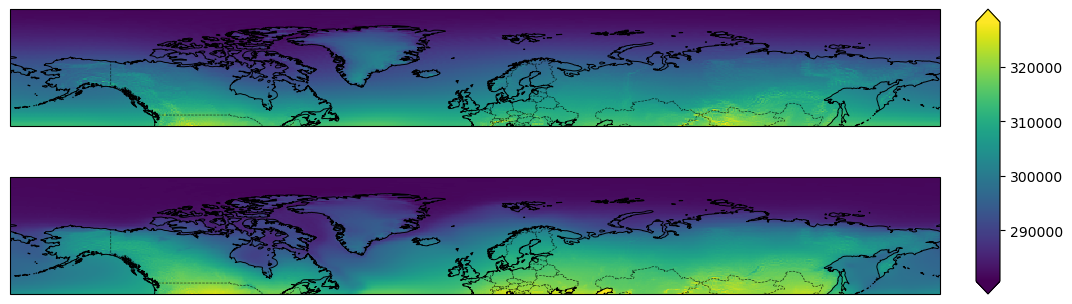

In [29]:
fig, ax = plt.subplots(2, 1, figsize=(12,4), subplot_kw={'projection': ccrs.PlateCarree()})

contour=ax[0].pcolormesh(clim_5000.longitude, clim_5000.latitude, clim_5000)

contour=ax[1].pcolormesh(clim_50.longitude, clim_50.latitude, clim_50)

for axs in ax.flatten():
    axs.grid()
    axs.add_feature(cf.COASTLINE, linewidth=0.7)
    axs.add_feature(cf.BORDERS, linewidth=0.5, linestyle='--', alpha=0.7)

all_axes = ax[:]
bbox = mtransforms.Bbox.union([ax.get_position() for ax in all_axes])
cbar_width = 0.02
cbar_pad = 0.01
cax = fig.add_axes([
    bbox.x1 + cbar_pad + cbar_width,                       
    bbox.y0,
    cbar_width,
    bbox.height,          
])
cb = fig.colorbar(contour, orientation='vertical', cax=cax,
                 extend='both', shrink=0.8)      # arrows for out-of-range values
